# **Libraries**
---
The libraries used throughout the workflow are imported: utilities, visualization, data manipulation, synthetic dataset generation for regression and classification, decision trees, data splitting and cross-validation, and evaluation metrics. MSE, RMSE, and MAE are used for regression, and precision and recall are used for classification.

In [1]:
# Utils
# ==============================================================================
import warnings

# Plot
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

# Data
# ==============================================================================
import numpy as np
import pandas as pd
from sklearn.datasets import make_friedman1, make_regression, make_classification

# Model
# ==============================================================================
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

# Metrics
# ==============================================================================
from sklearn.metrics import (
    mean_squared_error,
    root_mean_squared_error,
    mean_absolute_error,
    recall_score,
    precision_score)

# **Info**
---

**@By**: Steven Bernal

**@Nickname:** Kaiziferr

**@Git**: https://github.com/Kaiziferr

# **Data context**
---
**Project context**

The objective of this project is to demonstrate the **post-pruning** process in decision trees through **Cost-Complexity Pruning**. In this approach, the tree is fully grown, and the branches whose contribution does not offset the penalty defined by the ccp_alpha parameter are then removed. The process is applied to two problems: a regression problem and a binary classification problem.

**Data source**

Synthetic datasets were chosen because they provide a controlled and educational environment, designed specifically to explain the post-pruning process in decision trees.

Working with real-world datasets usually requires considerable preprocessing effort, such as data cleaning, handling missing values, correcting inconsistencies, and transforming variables. Although these steps are essential in any data science workflow, they are outside the scope of this exposition.

**Data description**

A nonlinear synthetic dataset is generated for the regression problem (make_friedman1), and an independent dataset is generated for the classification problem (make_classification).

**Objectives**

- Compute the cost-complexity pruning path of a regression tree and a classification tree.
- Select ccp_alpha with three different criteria: a general performance metric on validation, a problem-specific metric on validation, and cross-validation.
- Compare the unpruned tree with the pruned trees on the test set.

# **Configuration**
---
The global configuration of the run is defined. The seaborn `darkgrid` style is applied to the plots, and the random seed `12354` is set. This seed is used in data generation, data splits, and models to ensure reproducibility. Warning messages are also suppressed to produce cleaner outputs.

In [2]:
sns.set(style="darkgrid")
random_seed = 12354
warnings.filterwarnings('ignore')

# **Utilities**
---
The two helper functions used in the regression and classification sections are defined. They are placed before those sections so that the notebook can be run in order.

- **select_best_ccp_alphas():** obtains the position of the best candidate according to the validation score (maximum), the validation metric, and cross-validation. With typ='R', the metric and cross-validation are minimized (MAE). With typ='C', they are maximized (recall). The function returns a table with the ccp_alpha, criterion value, impurity, nodes, and depth of each candidate, along with the three positions. In case of ties, list.index() returns the first position, that is, the smallest ccp_alpha.
- **cost_complexity_pruning_plot():** builds the six-plot panel (two rows by three columns) with the performance and complexity of the tree as a function of ccp_alpha.

In [3]:
def select_best_ccp_alphas(
    ccp_alphas,
    score_val,
    val_scores,
    cro_cv,
    node_counts,
    impurities,
    depth,
    typ = 'R'
):

  i_score_val = score_val.index(max(score_val))
  i_metric= 0
  i_cross = 0
  if typ=='R':
    i_metric = val_scores.index(min(val_scores))
    i_cross = cro_cv.index(min(cro_cv))
  elif typ=='C':
    i_metric = val_scores.index(max(val_scores))
    i_cross = cro_cv.index(max(cro_cv))

  dta = [
        (
            'Score',
            ccp_alphas[i_score_val],
            score_val[i_score_val],
            impurities[i_score_val],
            node_counts[i_score_val],
            depth[i_score_val],

        ),
        (
            'Metric',
            ccp_alphas[i_metric],
            val_scores[i_metric],
            impurities[i_metric],
            node_counts[i_metric],
            depth[i_metric],

        ),
        (
            'cv-n',
            ccp_alphas[i_cross],
            cro_cv[i_cross],
            impurities[i_cross],
            node_counts[i_cross],
            depth[i_cross],

        )
    ]
  dta = pd.DataFrame(dta, columns=
     ['', 'ccp_alphas', 'metric value', 'impurities', 'nodes', 'depth'])

  return dta, i_score_val, i_metric, i_cross




def cost_complexity_pruning_plot(
  i_score_val,
  i_metric,
  i_cross,
  ccp_alphas,
  impurities,
  node_counts,
  depth,
  train_scores,
  val_scores,
  cro_cv,
  score_trainer,
  score_val
):
  try:

    fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(15,10))
    ax[0,0].plot(ccp_alphas, score_trainer, marker="o", label="train", drawstyle="steps-post")
    ax[0,0].plot(ccp_alphas, score_val, marker="o", label="validation", drawstyle="steps-post")
    ax[0,0].set_xlabel("Alpha")
    ax[0,0].set_ylabel("Score")
    ax[0,0].set_title("Score vs alpha for training and testing validation")

    ax[0,0].axvline(ccp_alphas[i_score_val], linestyle='--', label=f'Best Alpha: {ccp_alphas[i_score_val]}', color='g')
    ax[0,0].axhline(score_val[i_score_val], linestyle='--', label=f'Best Score: {score_val[i_score_val]}', color='g')
    ax[0,0].legend()

    ax[0,1].plot(ccp_alphas, train_scores, marker="o", label="train", drawstyle="steps-post")
    ax[0,1].plot(ccp_alphas, val_scores, marker="o", label="validation", drawstyle="steps-post")
    ax[0,1].set_xlabel("Alpha")
    ax[0,1].set_ylabel("Metric")
    ax[0,1].set_title("Metric vs alpha for training and validation sets")
    ax[0,1].axvline(ccp_alphas[i_metric], linestyle='--', label=f'Best Alpha: {ccp_alphas[i_metric]}', color='brown')
    ax[0,1].axhline(val_scores[i_metric], linestyle='--', label=f'Best metric: {val_scores[i_metric]}', color='brown')
    ax[0,1].legend()

    ax[0,2].plot(ccp_alphas, cro_cv, marker="o", label="validation", drawstyle="steps-post")
    ax[0,2].set_xlabel("Alpha")
    ax[0,2].set_ylabel("Mean Score Cross Validation ")
    ax[0,2].set_title("Cross Validation vs alpha")
    ax[0,2].axvline(ccp_alphas[i_cross], linestyle='--', label=f'Best Alpha: {ccp_alphas[i_cross]}', color='olive')
    ax[0,2].axhline(cro_cv[i_cross], linestyle='--', label=f'Best Cross_v: {cro_cv[i_cross]}', color='olive')
    ax[0,2].legend()

    ax[1,0].plot(ccp_alphas, impurities, marker="o", drawstyle='steps-post')
    ax[1,0].set_xlabel("Effective alpha")
    ax[1,0].set_ylabel("Total impurity of leaves")
    ax[1,0].set_title("Total Impurity vs effective alpha for training set")

    ax[1,1].plot(ccp_alphas, node_counts, marker="o", drawstyle="steps-post")
    ax[1,1].set_xlabel("Alpha")
    ax[1,1].set_ylabel("Number of nodes")
    ax[1,1].set_title("Number of nodes vs alpha")

    ax[1,2].plot(ccp_alphas, depth, marker="o", drawstyle="steps-post")
    ax[1,2].set_xlabel("alpha")
    ax[1,2].set_ylabel("depth of tree")
    ax[1,2].set_title("Depth vs alpha")
    fig.tight_layout()
    plt.subplots_adjust(top=0.9)
  except Exception as e:
    print(e)

# **Regression**
---

The scikit-learn make_friedman1 function is used to generate a synthetic dataset with a nonlinear relationship between the predictor variables and the target variable:

- `2000` observations and 8 predictor variables are generated.
- According to the scikit-learn documentation, the target variable depends only on the first 5 variables, combined through a sine function, a quadratic term, and linear terms. The remaining 3 variables are unrelated to the target variable and act as noise.
- Gaussian noise with a standard deviation of 1.8 is added to the target variable. This noise cannot be predicted, so no model can reach zero error on new data.
- The previously defined random seed (12354) is used to ensure reproducibility.

In [4]:
X, y = make_friedman1(n_samples=2000, n_features=8, noise=1.8, random_state=random_seed)

## **Data split**
---
The dataset is split into training and test sets with train_test_split. 90% of the observations (1800) are assigned to the training set, and the remaining 10% (200) are reserved for the final model evaluation. The random seed is used so that the split is reproducible.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size = 0.9, random_state = random_seed)

The training set is split again: 85% is kept to train the trees, and 15% is used as the validation set. Starting from 1800 observations, approximately 1530 training observations and 270 validation observations are obtained.

At the end of the process, there are three subsets with different roles:

- **Training:** used to compute the pruning path, fit the trees, and run cross-validation.
- **Validation:** used to compare the ccp_alpha values and select the candidates.
- **Test:** reserved for the final evaluation and not involved in the selection of ccp_alpha.

In [6]:
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, train_size = 0.85, random_state = random_seed)

## **Model**
---
A regression decision tree is initialized with DecisionTreeRegressor, without growth restrictions. The previously defined random seed is used to ensure reproducibility.

In [7]:
model_regresion = DecisionTreeRegressor(random_state=random_seed)

The cost-complexity pruning path of the tree is computed with cost_complexity_pruning_path, using only the training set. Internally, scikit-learn fits a full tree (ccp_alpha=0) and goes through the sequence of successive prunings. The method returns:

- **ccp_alphas:** the effective ccp_alpha values at which the tree structure changes.
- **impurities:** the total impurity of the leaves after each pruning step. In regression, the impurity corresponds to the mean squared error of each leaf.

Computing the path only with the training data prevents information from the validation or test sets from influencing the candidate values.

In [8]:
cost = model_regresion.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas, impurities = cost.ccp_alphas, cost.impurities

Each candidate ccp_alpha value obtained from the pruning path is evaluated. For each value, a tree is trained, and performance and complexity metrics are recorded:

- **Cross-validation:** mean MAE from 10-fold cross-validation on the training set (cro_cv). scikit-learn returns the MAE with a negative sign, so it is multiplied by -1 to express it as a positive error.
- **R²:** coefficient of determination on training (score_trainer) and validation (score_val).
- **MAE:** mean absolute error on training (train_scores) and validation (val_scores).
- **Complexity:** number of nodes (node_counts) and maximum depth (depth) of each tree.

The validation set (X_val, y_val) is used to compare the trees and select ccp_alpha. The test set (X_test, y_test) is not involved in this process because it must remain isolated from model selection decisions. Using it to choose ccp_alpha would introduce information from the data reserved for the final evaluation and would compromise its role as an independent measure of generalization.

In [9]:
# Initialize lists to store the number of nodes for each pruned tree
node_counts = []
# Initialize a list to store the maximum depth of each pruned tree
depth = []
# Initialize a list to store the MAE on the training set for each ccp_alpha
train_scores = []
# Initialize a list to store the MAE on the validation set for each ccp_alpha
val_scores = []
# Initialize a list to store each trained decision tree
models = []
# Initialize a list to store the mean cross-validation MAE for each ccp_alpha
cro_cv = []
# Initialize a list to store the R² score on the training set for each ccp_alpha
score_trainer = []
# Initialize a list to store the R² score on the validation set for each ccp_alpha
score_val = []
# Evaluate a decision tree for each candidate ccp_alpha
for ccp_alpha in ccp_alphas:
  # Initialize a decision tree with the current ccp_alpha value
  model = DecisionTreeRegressor(random_state=random_seed, ccp_alpha=ccp_alpha)
  # Evaluate the model using 10-fold cross-validation on the training set
  # and convert the negative MAE returned by scikit-learn to the standard positive MAE
  cro_cv.append(-1*cross_val_score(model, X_train, y_train, cv=10, scoring='neg_mean_absolute_error').mean())
  # Fit the tree using the training data
  model.fit(X_train, y_train)
  # Store the R² score obtained on the training set
  score_trainer.append(model.score(X_train, y_train))
  # Store the R² score obtained on the validation set
  score_val.append(model.score(X_val, y_val))
  # Store the number of nodes in the pruned tree
  node_counts.append(model.tree_.node_count)
  # Store the maximum depth of the pruned tree
  depth.append(model.tree_.max_depth)
  # Calculate and store the MAE on the training set
  train_scores.append(mean_absolute_error(y_train, model.predict(X_train)))
  # Calculate and store the MAE on the validation set
  val_scores.append(mean_absolute_error(y_val, model.predict(X_val)))
  # Store the trained model for each ccp_alpha
  models.append(model)

The select_best_ccp_alphas() function, defined in the **Utilities** section, is used to select the best ccp_alpha according to three criteria.

The function receives:

- **ccp_alphas:** candidate ccp_alpha values.
- **score_val:** R² obtained on validation.
- **val_scores:** MAE obtained on validation.
- **cro_cv:** mean MAE from 10-fold cross-validation.
- **node_counts, impurities, and depth:** number of nodes, total impurity, and depth of each tree.
- **typ='R':** indicates that the problem is a regression problem. In this case, the validation MAE and the cross-validation MAE are minimized. With typ='C', they are maximized.

The function returns:

- **dta:** a table with the best candidate for each criterion.
- **i_score_val, i_metric, and i_cross:** the positions, within the received lists, of the best candidate according to the validation R², the validation metric, and cross-validation.

All lists are passed with [1:-1]. This excludes the first value of the path (ccp_alpha=0, the unpruned tree) and the last one (the tree reduced to the root node).

In [10]:
dta, i_score_val, i_metric, i_cross = select_best_ccp_alphas(
    ccp_alphas[1:-1],
    score_val[1:-1],
    val_scores[1:-1],
    cro_cv[1:-1],
    node_counts[1:-1],
    impurities[1:-1],
    depth[1:-1],
    typ = 'R'
)
dta

,,ccp_alphas,metric value,impurities,nodes,depth
0,Score,0.058314,0.646198,6.318928,99,9
1,Metric,0.058314,2.483994,6.318928,99,9
2,cv-n,0.035501,2.531112,5.113928,149,10


The table summarizes the best ccp_alpha according to each criterion:

- **Score:** ccp_alpha with the highest validation R².
- **Metric:** ccp_alpha with the lowest validation MAE.
- **cv-n:** ccp_alpha with the lowest mean MAE from 10-fold cross-validation.

The metric value column contains the value of the corresponding criterion, and the impurities, nodes, and depth columns describe the complexity of the selected tree.

- **Score and Metric** select the same value, `ccp_alpha = 0.058314`. The tree obtains a validation R² of 0.6462 and a validation MAE of 2.4840, with **99 nodes** and depth 9.
- **cv-n** selects a smaller value, `ccp_alpha = 0.035501`, with a mean cross-validation MAE of 2.5311. A smaller ccp_alpha implies less intense pruning. The tree keeps **149 nodes** and depth 10.

R² and MAE agree on the same ccp_alpha. This agreement supports the choice of that value, although the two results are not independent evidence: both metrics are computed on the same validation set of about 270 observations. Cross-validation, which averages ten splits of the training set, prefers a slightly larger tree.

A six-plot panel is generated with the cost_complexity_pruning_plot() function, defined in the Utilities section. All plots share the X axis, which corresponds to ccp_alpha:

- **Top row:** performance. R² (Score) on training and validation, MAE (Metric) on training and validation, and mean cross-validation MAE. The dotted lines mark the best ccp_alpha and the best value of each criterion.
- **Bottom row:** structural cost of pruning. Total leaf impurity, number of nodes, and tree depth.

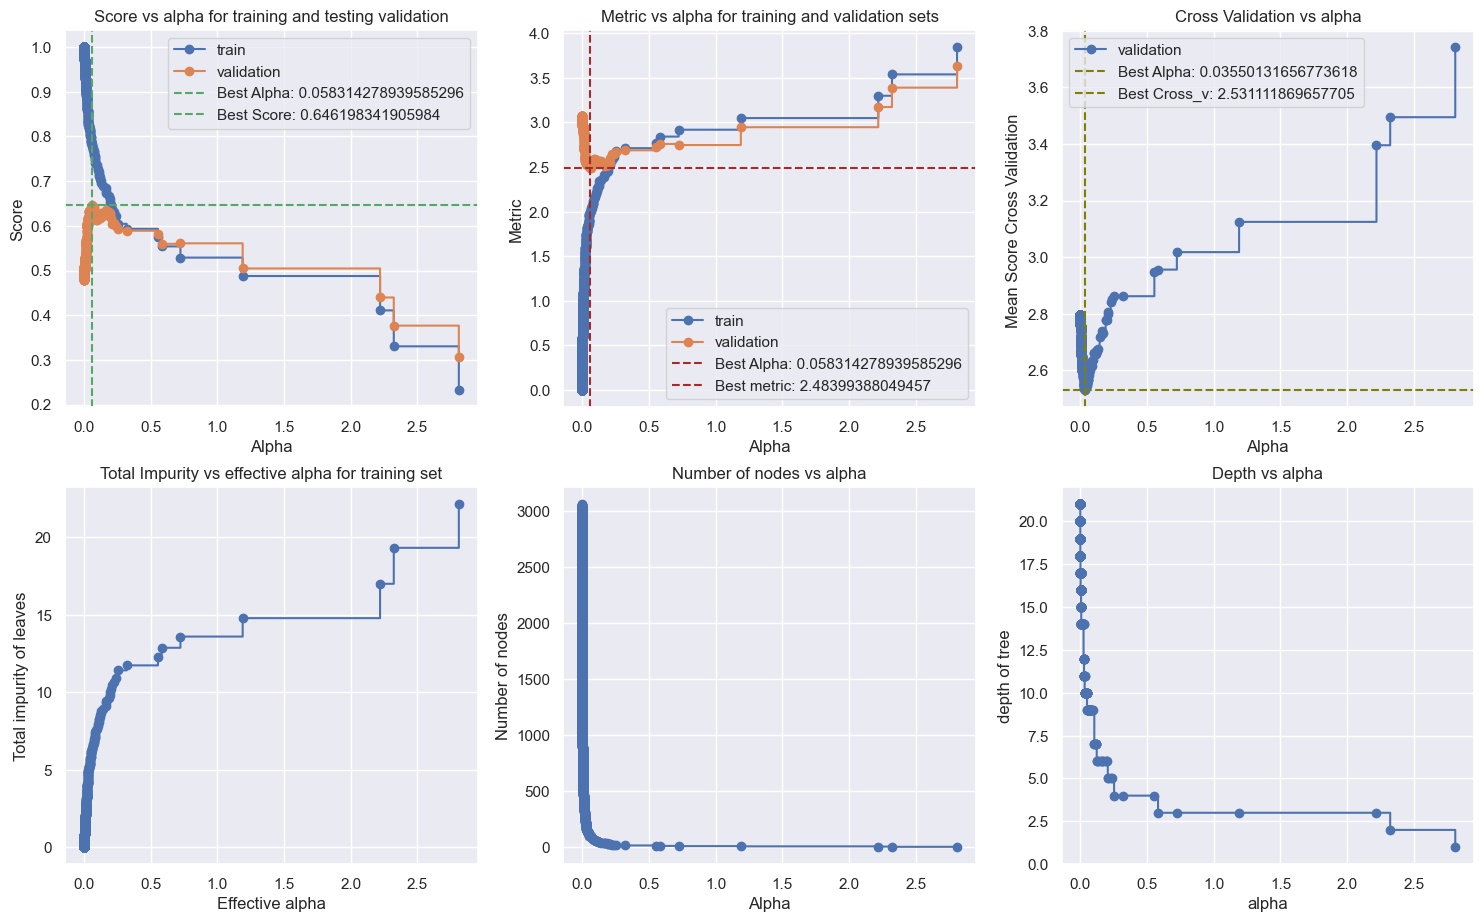

In [11]:
cost_complexity_pruning_plot(
    i_score_val,
    i_metric,
    i_cross,
    ccp_alphas[1:-1],
    impurities[1:-1],
    node_counts[1:-1],
    depth[1:-1],
    train_scores[1:-1],
    val_scores[1:-1],
    cro_cv[1:-1],
    score_trainer[1:-1],
    score_val[1:-1])


The top row identifies the point of best generalization, and the bottom row shows the structural simplification produced by pruning. Most ccp_alpha values are concentrated near 0, so in several panels the first points overlap next to the vertical axis.

**Score vs alpha (training and validation)**
- With ccp_alpha close to 0, the tree reaches an R² of `1.0` on training, but on validation it stays close to 0.49. The difference shows the overfitting of the unpruned tree.
- As ccp_alpha increases, pruning reduces the complexity of the tree, and the training and validation curves move closer together.
- The best validation R² is reached at ccp_alpha = 0.058314, marked with the vertical line, with an approximate value of `0.646`.
- Beyond that point, both curves decrease. With ccp_alpha close to 2.8, the validation R² drops to about 0.31. Excessive pruning removes useful structure, and the model moves into underfitting.

**Metric vs alpha (MAE on training and validation)**
- The training MAE increases progressively from 0 as the tree is pruned. This is expected because the model loses flexibility.
- The validation MAE starts at about 3.0, decreases to its minimum, and then increases again.
- The minimum validation error is again reached at ccp_alpha = 0.058314, with an approximate MAE of `2.48`.

**Cross Validation vs alpha**
- The lowest mean cross-validation MAE is obtained at ccp_alpha = 0.035501, with an approximate value of 2.53.
- This value is slightly smaller than the one selected with the validation set (0.058314). In other words, cross-validation favors slightly less intense pruning.
- For high ccp_alpha values, the cross-validation MAE grows to about 3.75, the same underfitting pattern observed on validation.

**Total Impurity vs effective alpha**
- The total leaf impurity increases as ccp_alpha grows, because pruning removes splits that previously reduced local impurity.
- The increase is very fast at the beginning, in the area where the points are concentrated, and then advances in more widely spaced jumps up to about 22.
- This plot represents the structural cost of simplifying the tree, not its predictive performance.

**Number of nodes vs alpha**
- The unpruned tree has about `3000 nodes`. Even small ccp_alpha values reduce the number of nodes drastically.
- Most of the simplification occurs in the early stages of pruning. The tree selected by R² and MAE keeps 99 nodes.

**Depth vs alpha**
- The initial tree has a depth of `21 levels`.
- Depth decreases quickly as ccp_alpha increases. The selected tree has depth 9, and with the highest values of the path it drops to 1.

Overall, pruning reduces the tree from about 3000 nodes to 99 and improves the validation R² from about 0.49 to 0.646. In this problem, post-pruning improves generalization and produces a much simpler model.

## **Test set evaluation**
---
Four trees are evaluated on the test set (200 observations): the unpruned tree and the trees pruned with the ccp_alpha selected by each criterion. Each tree is trained with the training set, and three errors are measured:

- **MSE:** mean squared error. It penalizes large errors more heavily.
- **RMSE:** square root of the MSE, expressed in the same units as the target variable.
- **MAE:** mean absolute error, also in the units of the target variable.

For all three metrics, a lower value indicates better performance.

The first model is the unpruned tree with the default configuration.

In [12]:
model_regresion = DecisionTreeRegressor(random_state=random_seed)

model_regresion.fit(X_train, y_train)
y_predict = model_regresion.predict(X_test)

print(
    f'MSE: {mean_squared_error(y_test, y_predict)}',
    f'RMSE: {root_mean_squared_error(y_test, y_predict)}',
    f'MAE: {mean_absolute_error(y_test, y_predict)}'
)

MSE: 12.799169870921562 RMSE: 3.57759274805302 MAE: 2.8069726954917424


The unpruned tree obtains an MSE of 12.7992, an RMSE of 3.5776, and an MAE of `2.8070`. This model represents the initial performance of the algorithm and serves as the baseline to determine whether post-pruning improves performance.

The second model uses the ccp_alpha selected by the Score criterion (highest validation R²), which corresponds to the first row of the table (dta.iloc[0,1] = 0.058314).

In [13]:
model_regresion = DecisionTreeRegressor(random_state=random_seed, ccp_alpha=dta.iloc[0,1])

model_regresion.fit(X_train, y_train)
y_predict = model_regresion.predict(X_test)
print(
    f'MSE: {mean_squared_error(y_test, y_predict)}',
    f'RMSE: {root_mean_squared_error(y_test, y_predict)}',
    f'MAE: {mean_absolute_error(y_test, y_predict)}'
)

MSE: 10.276071165396607 RMSE: 3.205631164902882 MAE: 2.6389742307818915


With the ccp_alpha selected by R², all three errors decrease compared with the unpruned tree:

- The MSE drops from 12.7992 to 10.2761, a reduction of 19.7%.
- The RMSE drops from 3.5776 to 3.2056, a reduction of 10.4%.
- The MAE drops from 2.8070 to `2.6390`, a reduction of 6.0%.

The selected configuration allows the tree to generate predictions closer to the actual values, with a tree of 99 nodes instead of about 3000.

The third model uses the ccp_alpha selected by the Metric criterion (lowest validation MAE), which corresponds to the second row of the table (dta.iloc[1,1]).

In [14]:
model_regresion = DecisionTreeRegressor(random_state=random_seed, ccp_alpha=dta.iloc[1,1])

model_regresion.fit(X_train, y_train)
y_predict = model_regresion.predict(X_test)
print(
    f'MSE: {mean_squared_error(y_test, y_predict)}',
    f'RMSE: {root_mean_squared_error(y_test, y_predict)}',
    f'MAE: {mean_absolute_error(y_test, y_predict)}'
)

MSE: 10.276071165396607 RMSE: 3.205631164902882 MAE: 2.6389742307818915


The results are identical to those of the previous model. This is expected, because the Score and Metric criteria selected the same ccp_alpha (0.058314) and, with the same seed, they produce exactly the same tree. There is no performance difference between these two approaches.

The fourth model uses the ccp_alpha selected by cross-validation, which corresponds to the third row of the table (dta.iloc[2,1] = 0.035501).

In [15]:
model_regresion = DecisionTreeRegressor(random_state=random_seed, ccp_alpha=dta.iloc[2,1])

model_regresion.fit(X_train, y_train)
y_predict = model_regresion.predict(X_test)
print(
    f'MSE: {mean_squared_error(y_test, y_predict)}',
    f'RMSE: {root_mean_squared_error(y_test, y_predict)}',
    f'MAE: {mean_absolute_error(y_test, y_predict)}'
)

MSE: 9.37832500465239 RMSE: 3.0624051013300626 MAE: 2.499784994183172


The tree selected by cross-validation obtains the lowest errors among the evaluated models:

- The MSE drops to 9.3783, a reduction of 26.7% compared with the unpruned tree.
- The RMSE drops to 3.0624, a reduction of 14.4%.
- The MAE drops to `2.4998`, a reduction of 10.9%.

This tree has 149 nodes, more than the tree selected with the validation set (99), and it still generalizes better on the test set. A possible explanation is that cross-validation averages ten splits and depends less on a single validation sample of about 270 observations. This explanation is a hypothesis and was not tested in the notebook.

As a reference, the noise added to the data has a standard deviation of 1.8. For Gaussian noise, the mean absolute error that cannot be removed is approximately 1.8 × 0.798 ≈ 1.44, so part of the MAE of 2.50 corresponds to the noise in the data and not to limitations of the model.

The comparison between the pruned models is made here for analysis purposes. If the final model were chosen based on its test result, the test set would no longer be an independent measure of performance.

### **Model comparison**
---
The unpruned tree and the three pruned candidates are gathered in a single table. Each tree is retrained with the training set, and its performance is measured on every data split:

- **ccp_alpha, nodes, and depth:** pruning parameter and complexity of the resulting tree.
- **MAE train, MAE val, MAE CV, and MAE test:** mean absolute error on training, validation, 10-fold cross-validation, and test. A lower value is better.
- **R2 train, R2 val, and R2 test:** coefficient of determination on training, validation, and test. A higher value is better.

The **MAE** is the main metric of this comparison. It expresses the mean error of the predictions in the same units as the target variable, so it directly indicates how wrong each tree is. R² indicates the proportion of the variability of the target variable that the model explains, that is, how well it fits the data, but on its own it does not indicate whether the prediction error is acceptable. For this reason, it is used as a complement.

Comparing the error on training with the error on validation and test makes it possible to detect overfitting. If a tree makes far fewer errors on the data it used for training than on new data, it is memorizing instead of learning generalizable patterns.

In [ ]:
# Compare the unpruned tree with the three pruned candidates on every data split
candidates_reg = {
    'Unpruned': 0.0,
    'Score (R2)': dta.iloc[0, 1],
    'Metric (MAE)': dta.iloc[1, 1],
    'cv-n (CV MAE)': dta.iloc[2, 1],
}
rows = []
for name, alpha in candidates_reg.items():
    tree = DecisionTreeRegressor(random_state=random_seed, ccp_alpha=alpha)
    # Mean MAE from 10-fold cross-validation on the training set
    cv_mae = -cross_val_score(tree, X_train, y_train, cv=10, scoring='neg_mean_absolute_error').mean()
    tree.fit(X_train, y_train)
    rows.append({
        'model': name,
        'ccp_alpha': alpha,
        'nodes': tree.tree_.node_count,
        'depth': tree.get_depth(),
        'R2 train': tree.score(X_train, y_train),
        'R2 val': tree.score(X_val, y_val),
        'R2 test': tree.score(X_test, y_test),
        'MAE train': mean_absolute_error(y_train, tree.predict(X_train)),
        'MAE val': mean_absolute_error(y_val, tree.predict(X_val)),
        'MAE CV': cv_mae,
        'MAE test': mean_absolute_error(y_test, tree.predict(X_test)),
    })
comparison_reg = pd.DataFrame(rows).set_index('model').round(4)
comparison_reg

,ccp_alpha,nodes,depth,R2 train,R2 val,R2 test,MAE train,MAE val,MAE CV,MAE test
model,,,,,,,,,,
Unpruned,0.0000,3059,21,1.0000,0.4917,0.5200,0.0000,3.0258,2.7902,2.8070
Score (R2),0.0583,99,9,0.7810,0.6462,0.6146,1.9906,2.4840,2.5774,2.6390
Metric (MAE),0.0583,99,9,0.7810,0.6462,0.6146,1.9906,2.4840,2.5774,2.6390
cv-n (CV MAE),0.0355,149,10,0.8228,0.6324,0.6483,1.8006,2.5453,2.5311,2.4998


The table summarizes the four regression trees. The analysis is organized into three parts:

1. **Each tree separately:** how its error changes from the training data to the validation data and from the validation data to the test data, and whether it shows overfitting.
2. **Comparison between trees:** the error of each pruned tree compared with the unpruned tree and with the other pruned trees, on validation, cross-validation, and test.
3. **The best tree.**

The main metric is the MAE: the mean error of each prediction, in units of the target variable. R² is used as a complement.

As a reference, the data include Gaussian noise with a standard deviation of 1.8, which no model can predict. This noise is equivalent to an MAE of approximately `1.44` (1.8 × 0.798). A tree that generalizes well should have a training error close to or above that value. A training error far below it indicates that the tree is fitting the noise.

**How the differences are calculated**

All differences in this analysis are calculated with the MAE values from the previous table:

- **Difference in units:** the starting MAE is subtracted from the final MAE. For example, tree 2 has an MAE of 1.9906 on training and 2.4840 on validation: 2.4840 − 1.9906 = 0.49. The error increased by 0.49 units when moving to the validation data.
- **Percentage change:** that difference is divided by the starting MAE and multiplied by 100. In the same example: 0.4934 / 1.9906 × 100 = 24.8%. In other words, the validation error is 24.8% higher than the training error.
- **Sign:** a positive value (+) indicates that the error increased, and a negative value (−) indicates that it decreased. For example, the unpruned tree goes from an MAE of 3.0258 on validation to 2.8070 on test: (2.8070 − 3.0258) / 3.0258 × 100 = −7.2%. Its error decreased by 7.2%.
- **Comparison between trees:** the starting MAE is that of the reference tree. For example, to compare tree 3 with the unpruned tree on test: (2.4998 − 2.8070) / 2.8070 × 100 = −10.9%. Tree 3 makes 10.9% less error than the unpruned tree.
- **Case without a percentage:** when the starting MAE is 0, as with the unpruned tree on training, it is not possible to divide by 0. In that case, only the difference in units is reported.

#### **Part 1. Analysis of each tree**

**Tree 1. Unpruned (ccp_alpha = 0, 3059 nodes, depth 21)**

- **Training:** MAE of `0` and R² of 1.0. The tree makes no errors on the data it used for training. This error is far below the noise level (1.44), which means that the tree memorized every observation, including its noise.
- **Validation:** MAE of 3.0258 and R² of 0.4917. From training to validation, the error rises from 0 to 3.03 units. This is the largest jump among the four trees: what the tree memorized is not useful for predicting data it has not seen. In cross-validation, the mean MAE is 2.7902, also far from 0.
- **Test:** MAE of 2.8070 and R² of 0.5200. From validation to test, the error drops from 3.0258 to 2.8070, that is, 0.22 units less (−7.2%). This difference indicates that the error of the unpruned tree changes considerably depending on the split used for evaluation. A possible cause is that such a large tree is very sensitive to which observations each split contains, although this explanation was not tested. The cross-validation MAE (2.7902) was much closer to the test MAE (a difference of 0.02).
- **Overfitting:** severe. The tree goes from an error of 0 on training to 2.81 on test, and its R² drops from 1.0 to 0.52. It performs perfectly on the data it memorized and much worse on new data.

**Tree 2. Pruned with the Score and Metric criteria (ccp_alpha = 0.058314, 99 nodes, depth 9)**

The Score (highest validation R²) and Metric (lowest validation MAE) criteria selected the same ccp_alpha. For this reason, their two rows in the table are identical and correspond to a single tree.

- **Training:** MAE of 1.9906 and R² of 0.7810. The training error is no longer 0 and is above the noise level (1.44), so the tree stopped memorizing the noise.
- **Validation:** MAE of 2.4840 and R² of 0.6462. From training to validation, the error rises from 1.9906 to 2.4840, that is, 0.49 units more (+24.8%), a much smaller jump than that of the unpruned tree (3.03 units). In cross-validation, the mean MAE is 2.5774.
- **Test:** MAE of 2.6390 and R² of 0.6146. From validation to test, the error rises from 2.4840 to 2.6390, that is, 0.16 units more (+6.2%). This increase is expected: the ccp_alpha of this tree was chosen by looking for the lowest error precisely on the validation set, so its validation result is optimistic. The cross-validation MAE (2.5774) better anticipated the test error (a difference of 0.06).
- **Overfitting:** reduced, but not eliminated. The tree goes from an error of 1.99 on training to 2.64 on test, a difference of 0.65 units (+32.6%), and its R² drops from 0.78 to 0.61. The difference is less than one quarter of that of the unpruned tree (2.81).

**Tree 3. Pruned with the cv-n criterion (ccp_alpha = 0.035501, 149 nodes, depth 10)**

This tree was selected with the lowest mean cross-validation MAE.

- **Training:** MAE of 1.8006 and R² of 0.8228. The training error is above the noise level (1.44), although it is lower than that of tree 2 (1.99), because this tree has more nodes and fits the training data somewhat more closely.
- **Validation:** MAE of 2.5453 and R² of 0.6324. From training to validation, the error rises from 1.8006 to 2.5453, that is, 0.74 units more (+41.4%). This jump is larger than that of tree 2 (0.49 units) but much smaller than that of the unpruned tree (3.03 units). In cross-validation, the mean MAE is 2.5311, the lowest of the four trees.
- **Test:** MAE of `2.4998` and R² of 0.6483. From validation to test, the error drops from 2.5453 to 2.4998, that is, 0.05 units less (−1.8%). Compared with cross-validation, it drops from 2.5311 to 2.4998, 0.03 units less (−1.2%). It is the only pruned tree whose test error does not worsen with respect to its previous estimates: cross-validation anticipated the error on new data quite accurately.
- **Overfitting:** reduced, but not eliminated. The tree goes from an error of 1.80 on training to 2.50 on test, a difference of 0.70 units (+38.8%), and its R² drops from 0.82 to 0.65. The difference is similar to that of tree 2 (0.65) and much smaller than that of the unpruned tree (2.81).

#### **Part 2. Comparison between trees**

**On validation (MAE val)**

- Compared with the unpruned tree (3.0258), tree 2 reduces the error to 2.4840, that is, 0.54 units less (−17.9%). Tree 3 reduces it to 2.5453, 0.48 units less (−15.9%).
- Between the pruned trees, tree 2 has an error 0.06 units lower than tree 3 (2.4840 versus 2.5453). This advantage should be interpreted with caution, because tree 2 was chosen with this same validation set.

**On cross-validation (MAE CV)**

- Compared with the unpruned tree (2.7902), tree 2 reduces the error to 2.5774, 0.21 units less (−7.6%). Tree 3 reduces it to 2.5311, 0.26 units less (−9.3%).
- Between the pruned trees, tree 3 now has an error 0.05 units lower than tree 2 (2.5311 versus 2.5774).

**On test (MAE test)**

- Compared with the unpruned tree, which is wrong by 2.81 units on average in each prediction, tree 2 is wrong by 2.64: each prediction is 0.17 units closer to the actual value, 6% less error. Tree 3 is wrong by 2.50: each prediction is 0.31 units closer to the actual value, 11% less error.
- Between the pruned trees, tree 3 is wrong by 2.4998 versus 2.6390 for tree 2, that is, 0.14 units less: (2.4998 − 2.6390) / 2.6390 × 100 = −5.3%. Its improvement over the unpruned tree is almost twice as large.
- In terms of R², the unpruned tree explains about 52% of the variation of the target variable on test, tree 2 about 61%, and tree 3 about 65%.

**Tree size**

- Tree 2 has 99 nodes and tree 3 has 149, compared with 3059 for the unpruned tree. They keep, respectively, 3 and 5 out of every 100 nodes, and both still predict better. Fewer nodes mean fewer decision rules, so the models are easier to interpret.

**The ranking changes depending on the evaluation data**

- On validation, the best tree is tree 2. On cross-validation and test, the best is tree 3.
- Cross-validation ranked the trees in the same way as the test set, while a single validation split of 270 observations did not. This shows that choosing with a single split can lead to a different decision from the one that would be made with more evaluation data.

#### **Part 3. Which tree was best?**

**Tree 3**, selected by cross-validation, is the one that makes the smallest error on new data: its test MAE is 2.4998, 0.14 units less than tree 2 and 0.31 less than the unpruned tree. In addition, its test error matched what cross-validation anticipated, so its performance is the most predictable of the three. Its difference between training and test (0.70) is only slightly larger than that of tree 2 (0.65), but that difference is not the only criterion. What matters in practice is the error on new data, and on that point tree 3 is the best. Tree 2 remains a good alternative if a smaller tree is preferred (99 nodes versus 149).

### **Regression conclusions**
---
- **Post-pruning reduced the error on new data.** The unpruned tree, with 3059 nodes and depth 21, obtained a test MAE of 2.8070. The pruned trees reduced that error to 2.6390 (99 nodes) and to `2.4998` (149 nodes).
- **The best model was the one selected by cross-validation.** It obtained the lowest test MAE (2.4998), 0.31 units less than the unpruned tree (−10.9%), with a tree about 20 times smaller.
- **The unpruned tree memorized the noise.** Its training MAE was 0, below the error of approximately 1.44 that corresponds to the noise in the data. The pruned trees have a training error of 1.80 to 1.99, above that level, and their difference between training and test decreased from 2.81 to about 0.7 units.
- **Part of the overfitting remains.** The pruned trees still make between 0.65 and 0.70 units more error on test than on training.
- **Cross-validation was a more reliable estimate.** The tree chosen with a single validation split had a validation error (2.4840) lower than its test error (2.6390). The tree chosen by cross-validation kept a similar error on cross-validation (2.5311) and on test (2.4998).
- **The validation R² and MAE criteria agreed on the same ccp_alpha.** Both produced the same 99-node tree, but they are not independent evidence, because they are computed on the same validation set.
- **Limitations:** the results come from synthetic data, a single validation and test split, and a test set of 200 observations. The comparison of the models on the test set is made for analysis purposes. If the final model were chosen based on this result, the test set would no longer be an independent measure.

# **Classification**
---

A synthetic dataset for a binary classification problem is generated with the scikit-learn make_classification function:

- `2000` observations and 8 predictor variables are generated, of which 5 are informative, that is, they contain the signal that makes it possible to distinguish between the two classes. No redundant variables are included.
- To simulate a scenario closer to a real problem, class imbalance is introduced with weights=[0.75, 0.25]: about 75% of the observations belong to the majority class (0) and 25% to the minority class (1).
- A single cluster per class is specified, which produces more clearly defined decision boundaries.
- The random seed ensures the reproducibility of the dataset.

In [17]:
X, y = make_classification(
    n_samples=2000,
    n_features=8,
    n_informative=5,
    n_redundant=0,
    random_state=random_seed,
    n_clusters_per_class=1,
    weights=[0.75, 0.25])

## **Data split**
---
The dataset is split into three independent subsets to maintain a rigorous evaluation workflow. First, 80% of the data (1600 observations) is assigned to the training set, and the remaining 20% (400) is reserved as the test set for the final evaluation.

In [18]:
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=random_seed, stratify=y)

Next, the training set is split into 85% to train the models (1360 observations) and 15% for validation (240). The validation set is used to select ccp_alpha, while the test set remains isolated to evaluate the generalization of the final model without bias.

In [19]:
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, train_size=0.85, random_state=random_seed, stratify=y_train)

The stratify parameter is applied in both splits to preserve the original class distribution in the training, validation, and test sets. In this way, the class imbalance remains constant throughout the workflow. This point is important because recall and precision are calculated on the minority class, and a split without stratification could leave very few positive cases in validation.

## **Model**
---
A classification decision tree (DecisionTreeClassifier) is initialized with a fixed seed to ensure reproducibility. At this stage, no pruning or additional hyperparameter is applied: the tree is trained with its default configuration before its complexity is evaluated and optimized.

In [20]:
model_clasification = DecisionTreeClassifier(random_state=random_seed)

The cost-complexity pruning path of the classification tree (model_clasification) is computed with the training set, and the ccp_alphas and impurities values are extracted. These values are used as candidate pruning parameters in the subsequent evaluation.

In classification, the impurity of each leaf is measured with the Gini index, the default criterion of DecisionTreeClassifier. For this reason, the path must be computed with the classifier and not with the regression tree from the previous section. Each impurity criterion produces different ccp_alpha values, and only those of the classifier match the points at which its structure changes.

In [21]:
cost = model_clasification.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas, impurities = cost.ccp_alphas, cost.impurities

For each ccp_alpha value, a classification tree is initialized and evaluated:

- **Cross-validation:** mean recall from 10-fold cross-validation on the training set (cro_cv).
- **Accuracy:** recorded on training (score_trainer) and validation (score_val), using the classifier's score method.
- **Recall:** recorded on training (train_scores) and validation (val_scores).
- **Complexity:** number of nodes (node_counts) and maximum depth (depth) of each tree.

Recall measures the proportion of actual positive cases (minority class) that the model identifies. It is used as the specific metric because, with imbalanced classes, accuracy can be high even when the model fails on the minority class.

In [22]:
# Initialize lists to store the number of nodes for each pruned tree
node_counts = []
# Initialize a list to store the maximum depth of each pruned tree
depth = []
# Initialize a list to store the Recall on the training set for each ccp_alpha
train_scores = []
# Initialize a list to store the Recall on the validation set for each ccp_alpha
val_scores = []
# Initialize a list to store each trained decision tree
models = []
# Initialize a list to store the mean cross-validation Recall for each ccp_alpha
cro_cv = []
# Initialize a list to store the accuracy score on the training set for each ccp_alpha
score_trainer = []
# Initialize a list to store the accuracy score on the validation set for each ccp_alpha
score_val = []
# Evaluate a decision tree for each candidate ccp_alpha
for ccp_alpha in ccp_alphas:
  # Initialize a decision tree with the current ccp_alpha value
  model = DecisionTreeClassifier(random_state=random_seed, ccp_alpha=ccp_alpha)
  # Evaluate the model using 10-fold cross-validation on the training set
  cro_cv.append(cross_val_score(model, X_train, y_train, cv=10, scoring='recall').mean())
  # Fit the tree using the training data
  model.fit(X_train, y_train)
  # Store the accuracy score obtained on the training set
  score_trainer.append(model.score(X_train, y_train))
  # Store the accuracy score obtained on the validation set
  score_val.append(model.score(X_val, y_val))
  # Store the number of nodes in the pruned tree
  node_counts.append(model.tree_.node_count)
  # Store the maximum depth of the pruned tree
  depth.append(model.tree_.max_depth)
  # Calculate and store the Recall on the training set
  train_scores.append(recall_score(y_train, model.predict(X_train)))
  # Calculate and store the Recall on the validation set
  val_scores.append(recall_score(y_val, model.predict(X_val)))
  # Store the trained model for each ccp_alpha
  models.append(model)

Three criteria are applied to select the best ccp_alpha:

- **Score:** the highest validation accuracy.
- **Metric:** the highest validation recall.
- **cv-n:** the highest mean cross-validation recall.

The number of nodes, total impurity, and depth columns are kept as additional information to characterize the complexity of the selected trees.

As in regression, all lists are passed with [1:-1] to exclude the unpruned tree and the tree reduced to the root.

In [23]:
dta, i_score_val, i_metric, i_cross = select_best_ccp_alphas(
    ccp_alphas[1:-1],
    score_val[1:-1],
    val_scores[1:-1],
    cro_cv[1:-1],
    node_counts[1:-1],
    impurities[1:-1],
    depth[1:-1],
    typ = 'C'
)
dta

,,ccp_alphas,metric value,impurities,nodes,depth
0,Score,0.002035,0.979167,0.036785,29,8
1,Metric,0.000725,0.933333,0.001451,91,11
2,cv-n,0.001348,0.906218,0.018538,51,10


The three criteria select different ccp_alpha values, with different levels of complexity:

- **Score (accuracy):** selects ccp_alpha = 0.002035, with a validation accuracy of `0.9792`. It produces the simplest tree of the three, with **29 nodes**, depth 8, and total impurity of 0.0368.
- **Metric (recall):** selects ccp_alpha = 0.000725, the first value of the path after 0, with a validation recall of 0.9333. That recall is repeated in the first values of the path, and in case of a tie, the function takes the first one. The tree keeps **91 nodes** and depth 11, only 4 nodes fewer than the unpruned tree.
- **cv-n (cross-validation):** selects ccp_alpha = 0.001348, with a mean cross-validation recall of 0.9062. It produces an intermediate complexity, with **51 nodes**, depth 10, and total impurity of 0.0185.

Overall, the three criteria show the balance between performance and complexity. The Score criterion obtained the highest value of its metric with the simplest tree. The Metric criterion applied minimal pruning, because the maximum validation recall was already reached at the first point of the path. In addition, the value 0.002035 selected by Score also reaches a validation recall of 0.9333, equal to the maximum, as shown in the second plot.

The same six-plot panel from the regression section is generated, now with the classification metrics:

- **Top row:** accuracy (Score) on training and validation, recall (Metric) on training and validation, and mean cross-validation recall. The dotted lines mark the best ccp_alpha and the best value of each criterion.
- **Bottom row:** total leaf impurity, number of nodes, and tree depth.

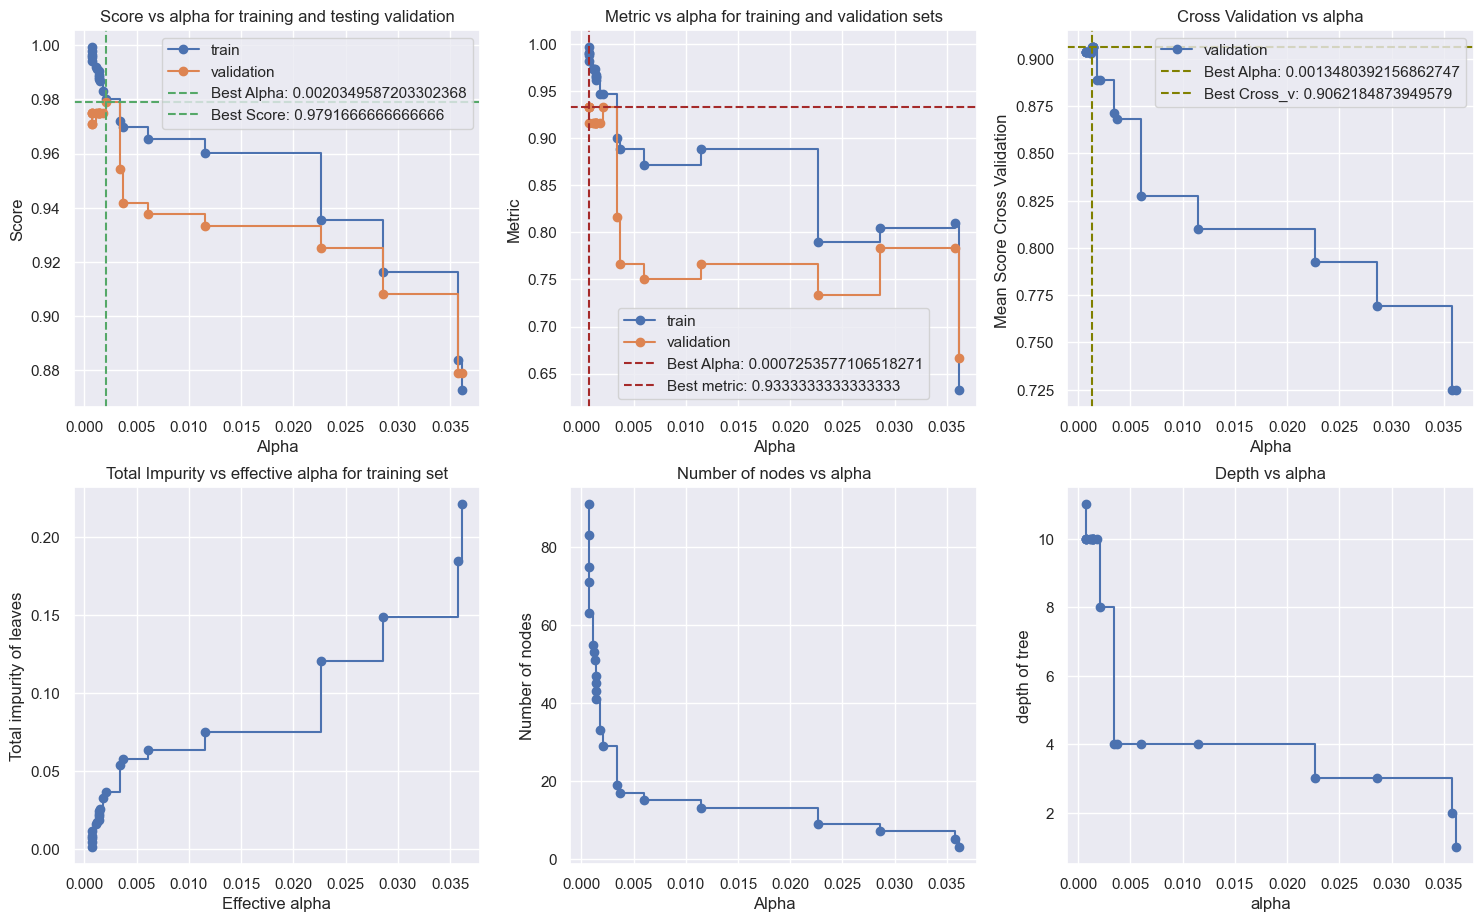

In [24]:
cost_complexity_pruning_plot(
    i_score_val,
    i_metric,
    i_cross,
    ccp_alphas[1:-1],
    impurities[1:-1],
    node_counts[1:-1],
    depth[1:-1],
    train_scores[1:-1],
    val_scores[1:-1],
    cro_cv[1:-1],
    score_trainer[1:-1],
    score_val[1:-1])

The top row identifies the point of best generalization according to accuracy, recall, and cross-validation, and the bottom row shows the structural cost of pruning.

**Score vs alpha (accuracy)**
- With the first value of the path, the tree keeps a complex structure and reaches an accuracy close to `1.0` on training (0.9993), while on validation it stays at 0.9708.
- As ccp_alpha increases, pruning becomes more intense and the training accuracy decreases continuously. In contrast, the validation accuracy rises to 0.975, stays at that level for a large part of the initial section, and reaches its maximum at ccp_alpha = 0.002035, with an approximate value of `0.9792`.
- Beyond that point, the validation accuracy drops steadily, from 0.954 to 0.879: excessive pruning starts to remove useful predictive structure.
- Under this criterion, ccp_alpha = 0.002035 is the best candidate, selected using only the training and validation sets.

**Metric vs alpha (recall)**
- The best validation recall, 0.9333, is obtained at ccp_alpha = 0.000725, the first value of the curve. Recall stays at that value in the first points, drops to 0.9167, returns to 0.9333 at ccp_alpha = 0.002035, and then falls below 0.82, down to 0.667 with the most intense pruning.
- The drop indicates that, from the perspective of this metric, moderate to strong pruning removes splits that are relevant for identifying the minority class.
- The difference between the alpha selected here and the one in the first plot does not mean that one of the results is incorrect. Each procedure optimizes a different criterion. The optimal ccp_alpha can change depending on the objective of the problem, for example, prioritizing accuracy, recall, or precision, so the selection must be aligned with the metric that best represents that objective.

**Cross Validation vs alpha**
- Each candidate is evaluated on the ten cross-validation splits of the training set, and a mean recall is obtained.
- The best value corresponds to ccp_alpha = 0.001348, with a mean recall of approximately `0.9062`. The same value is repeated in the following candidates up to about 0.0014, and the function takes the first one. Unlike the two previous plots, this result does not depend on a single validation split.
- The curve is fairly flat at the beginning: the mean recall is between 0.903 and 0.906 throughout the initial section. It then drops steadily to about 0.72.
- The selected value is smaller than that of the first criterion. This suggests that, when the tree is evaluated on several splits, keeping a larger part of the structure produces a slightly better average recall, although the difference from neighboring values is small.

**Total Impurity vs effective alpha**
- An increasing trend is observed: as ccp_alpha increases, the total leaf impurity, measured with the Gini index, increases from about 0 to about 0.22.
- Pruning removes splits that separated the observations into more homogeneous groups, so the remaining leaves are more heterogeneous.
- This plot does not indicate which alpha is best for prediction, but rather the structural cost of simplifying the tree.

**Number of nodes vs alpha**
- With the first value of the path, the tree has `91 nodes`, compared with 95 for the unpruned tree.
- The number of nodes decreases in steps along the entire path: 83, 75, 71, 63, 55, 53, 51, 47, 45, 43, 41, 33, 29, 19, 17, 15, 13, 9, 7, 5, and finally 3 nodes.
- Each value of the path produces a different tree, because the candidates were computed with the same classifier. Pruning does not necessarily remove one node at a time, but entire branches when their contribution to impurity reduction does not offset the complexity penalty.

**Depth vs alpha**
- The tree starts with a depth of `11 levels` and immediately drops to 10.
- Depth remains at 10 for a large part of the initial section, although the number of nodes drops from 83 to 33. It then goes to 8, to 4, and finally to 3, 2, and 1.
- This behavior shows that many prunings remove subtrees from the lower levels without immediately shortening the longest path of the tree.

## **Test set evaluation**
---
Four trees are evaluated on the test set (400 observations, of which 101 belong to the positive class): the unpruned tree and the trees pruned with the ccp_alpha of each criterion. Two metrics are measured on the positive class:

- **Precision:** proportion of positive predictions that are correct. Low precision indicates many false positives.
- **Recall:** proportion of actual positive cases that the model identifies. Low recall indicates many false negatives.

The first model is the unpruned tree with the default configuration.

In [25]:
model_clasification = DecisionTreeClassifier(random_state=random_seed)

model_clasification.fit(X_train, y_train)
y_predict = model_clasification.predict(X_test)

print(
    f'Precision: {precision_score(y_test, y_predict)}',
    f'Recall: {recall_score(y_test, y_predict)}'
)

Precision: 0.8703703703703703 Recall: 0.9306930693069307


The unpruned tree reaches a precision of 0.8704 (87.04%) and a recall of `0.9307` (93.07%). The model identifies 94 of the 101 positive cases, but of its 108 positive predictions, 14 are false positives. Because it is a fully grown tree, it serves as the baseline to compare the results of the different pruning criteria.

The second model uses the ccp_alpha selected by the Score criterion (accuracy), which corresponds to the first row of the table (dta.iloc[0,1] = 0.002035).

In [26]:
model_clasification = DecisionTreeClassifier(random_state=random_seed, ccp_alpha=dta.iloc[0,1])

model_clasification.fit(X_train, y_train)
y_predict = model_clasification.predict(X_test)

print(
    f'Precision: {precision_score(y_test, y_predict)}',
    f'Recall: {recall_score(y_test, y_predict)}'
)

Precision: 0.9387755102040817 Recall: 0.9108910891089109


With the ccp_alpha selected by accuracy, precision increases to `0.9388` (93.88%) and recall decreases slightly to 0.9109 (91.09%):

- False positives drop from 14 to 6, with 92 correct predictions out of 98 positive predictions.
- The model identifies 92 of the 101 positive cases, two fewer than the unpruned tree.

Accuracy-based pruning produced a model with more reliable positive predictions, at the cost of a small loss in the ability to identify all positive cases. This result is obtained with a tree of 29 nodes, compared with 95 for the unpruned tree, the simplest of the four models.

The third model uses the ccp_alpha selected by the Metric criterion (recall), which corresponds to the second row of the table (dta.iloc[1,1] = 0.000725).

In [27]:
model_clasification = DecisionTreeClassifier(random_state=random_seed, ccp_alpha=dta.iloc[1,1])

model_clasification.fit(X_train, y_train)
y_predict = model_clasification.predict(X_test)

print(
    f'Precision: {precision_score(y_test, y_predict)}',
    f'Recall: {recall_score(y_test, y_predict)}'
)

Precision: 0.8703703703703703 Recall: 0.9306930693069307


With the ccp_alpha selected by recall, the model reaches a precision of 0.8704 and a recall of 0.9307, values identical to those of the unpruned tree. This ccp_alpha removes only 4 of the 95 nodes, and on this test set that minimal pruning does not change any prediction. Although the criterion aimed to prioritize the identification of positive cases, the maximum validation recall was already reached at the first point of the path, and the tie was resolved in favor of the smallest ccp_alpha.

The fourth model uses the ccp_alpha selected by cross-validation, which corresponds to the third row of the table (dta.iloc[2,1] = 0.001348).

In [28]:
model_clasification = DecisionTreeClassifier(random_state=random_seed, ccp_alpha=dta.iloc[2,1])

model_clasification.fit(X_train, y_train)
y_predict = model_clasification.predict(X_test)

print(
    f'Precision: {precision_score(y_test, y_predict)}',
    f'Recall: {recall_score(y_test, y_predict)}'
)

Precision: 0.9108910891089109 Recall: 0.9108910891089109


With the ccp_alpha selected by cross-validation, the model reaches a precision of 0.9109 (91.09%) and a recall of 0.9109 (91.09%). It identifies 92 of the 101 positive cases and has 9 false positives out of 101 positive predictions.

The two metrics are equal, so this model has balanced performance between precision and recall. Compared with the Score criterion model, it obtains the same recall (0.9109) but lower precision (0.9109 versus 0.9388), that is, 3 more false positives. It is also more complex (51 nodes versus 29).

With 101 positive cases on test, each case is equivalent to about 1 percentage point of recall. The recall differences between the models are 0 to 2 cases, so they should be interpreted with caution.

### **Model comparison**
---
The unpruned tree and the three pruned candidates are gathered in a single table. Each tree is retrained with the training set, and its performance is measured on every data split:

- **ccp_alpha, nodes, and depth:** pruning parameter and complexity of the resulting tree.
- **Precision train, Precision val, and Precision test:** proportion of positive predictions that are correct on training, validation, and test.
- **Accuracy train, Accuracy val, and Accuracy test:** proportion of correct predictions over all observations.
- **Recall train, Recall val, Recall CV, and Recall test:** proportion of actual positive cases that the tree identifies, including 10-fold cross-validation.

For all three metrics, a higher value is better. The main metrics of this comparison are **precision** and **accuracy**, because they are where overfitting is observed and where the trees differ. Recall is analyzed as a secondary metric: the four trees obtain very similar values, and their differences on test are 0 to 2 positive cases.

Comparing performance on training with performance on validation and test makes it possible to detect overfitting. If a tree is much more accurate on the data it used for training than on new data, it is memorizing instead of learning generalizable patterns.

In [29]:
# Compare the unpruned tree with the three pruned candidates on every data split
candidates_cls = {
    'Unpruned': 0.0,
    'Score (accuracy)': dta.iloc[0, 1],
    'Metric (recall)': dta.iloc[1, 1],
    'cv-n (CV recall)': dta.iloc[2, 1],
}
rows = []
for name, alpha in candidates_cls.items():
    tree = DecisionTreeClassifier(random_state=random_seed, ccp_alpha=alpha)
    # Mean Recall from 10-fold cross-validation on the training set
    cv_recall = cross_val_score(tree, X_train, y_train, cv=10, scoring='recall').mean()
    tree.fit(X_train, y_train)
    y_tr, y_va, y_te = tree.predict(X_train), tree.predict(X_val), tree.predict(X_test)
    rows.append({
        'model': name,
        'ccp_alpha': alpha,
        'nodes': tree.tree_.node_count,
        'depth': tree.get_depth(),
        'Accuracy train': tree.score(X_train, y_train),
        'Accuracy val': tree.score(X_val, y_val),
        'Accuracy test': tree.score(X_test, y_test),
        'Recall train': recall_score(y_train, y_tr),
        'Recall val': recall_score(y_val, y_va),
        'Recall CV': cv_recall,
        'Recall test': recall_score(y_test, y_te),
        'Precision train': precision_score(y_train, y_tr),
        'Precision val': precision_score(y_val, y_va),
        'Precision test': precision_score(y_test, y_te),
    })
comparison_cls = pd.DataFrame(rows).set_index('model').round(4)
comparison_cls

,ccp_alpha,nodes,depth,Accuracy train,Accuracy val,Accuracy test,Recall train,Recall val,Recall CV,Recall test,Precision train,Precision val,Precision test
model,,,,,,,,,,,,,
Unpruned,0.0000,95,12,1.0000,0.9708,0.9475,1.0000,0.9333,0.9034,0.9307,1.0000,0.9492,0.8704
Score (accuracy),0.0020,29,8,0.9801,0.9792,0.9625,0.9475,0.9333,0.8886,0.9109,0.9731,0.9825,0.9388
Metric (recall),0.0007,91,11,0.9993,0.9708,0.9475,0.9971,0.9333,0.9034,0.9307,1.0000,0.9492,0.8704
cv-n (CV recall),0.0013,51,10,0.9904,0.9750,0.9550,0.9738,0.9167,0.9062,0.9109,0.9882,0.9821,0.9109


The table summarizes the four classification trees. The analysis is organized into three parts:

1. **Each tree separately:** how its metrics change from the training data to the validation data and from the validation data to the test data, and whether it shows overfitting.
2. **Comparison between trees:** the metrics of each pruned tree compared with the unpruned tree and with the other pruned trees, on validation, cross-validation, and test.
3. **The best tree.**

The main metrics are precision and accuracy. Recall is used as a complement. As a size reference, the validation set has 240 observations, of which 60 are positive cases, and the test set has 400 observations, of which 101 are positive cases.

**How the differences are calculated**

All differences in this analysis are calculated with the values from the previous table:

- **Difference in percentage points:** because accuracy, precision, and recall are proportions between 0 and 1, the difference is expressed in percentage points: (final value − starting value) × 100. For example, the unpruned tree has a precision of 1.0 on training and 0.8704 on test: (0.8704 − 1.0) × 100 = −12.96 percentage points.
- **Sign:** a negative value (−) indicates that the metric decreased, that is, the tree got worse. A positive value (+) indicates that it increased. This interpretation is the opposite of that of the MAE in regression, where a decrease meant an improvement.
- **Comparison between trees:** the starting value is that of the reference tree. For example, to compare the test accuracy of tree 2 with that of the unpruned tree: (0.9625 − 0.9475) × 100 = +1.50 percentage points.
- **Number of cases:** to make the differences more concrete, they are also expressed in observations. Accuracy is multiplied by the number of observations in the split (for example, 0.9625 × 400 = 385 correct predictions), and recall is multiplied by the number of positive cases (for example, 0.9109 × 101 = 92 positive cases identified).

#### **Part 1. Analysis of each tree**

**Tree 1. Unpruned (ccp_alpha = 0, 95 nodes, depth 12)**

- **Training:** precision, accuracy, and recall of `1.0`. The tree correctly classifies all the observations it used for training.
- **Validation:** precision of 0.9492, accuracy of 0.9708 (233 correct out of 240), and recall of 0.9333 (56 of 60 positive cases). From training to validation, precision drops from 1.0 to 0.9492 (−5.08 percentage points), accuracy from 1.0 to 0.9708 (−2.92 points), and recall from 1.0 to 0.9333 (−6.67 points). What the tree learned perfectly on training does not hold on data it has not seen. In cross-validation, the mean recall is 0.9034.
- **Test:** precision of 0.8704 (14 false positives), accuracy of 0.9475 (379 correct out of 400), and recall of 0.9307 (94 of 101 positive cases). From validation to test, precision drops again, from 0.9492 to 0.8704 (−7.88 points), and accuracy from 0.9708 to 0.9475 (−2.33 points). Recall remains almost the same (from 0.9333 to 0.9307, −0.26 points) and is above the cross-validation estimate (0.9034, +2.73 points).
- **Overfitting:** clear. Precision goes from 1.0 on training to 0.8704 on test, a drop of `12.96 percentage points`, and accuracy goes from 1.0 to 0.9475 (−5.25 points). The tree learned overly specific rules that, on new data, classify as positive cases that are not positive.

**Tree 2. Pruned with the Score criterion (ccp_alpha = 0.002035, 29 nodes, depth 8)**

This tree was selected with the highest validation accuracy.

- **Training:** precision of 0.9731, accuracy of 0.9801, and recall of 0.9475. The tree no longer classifies the training data perfectly, a sign that it stopped memorizing particular cases.
- **Validation:** precision of 0.9825 (1 false positive), accuracy of 0.9792 (235 correct out of 240), and recall of 0.9333 (56 of 60 positive cases). From training to validation, accuracy remains practically the same (from 0.9801 to 0.9792, −0.09 points), and precision even increases (from 0.9731 to 0.9825, +0.94 points). Recall drops from 0.9475 to 0.9333 (−1.42 points). This is the tree whose performance changes the least when moving to validation data, although this result is somewhat optimistic, because the ccp_alpha was chosen by looking for the best accuracy on that same set. In cross-validation, the mean recall is 0.8886.
- **Test:** precision of `0.9388` (6 false positives), accuracy of `0.9625` (385 correct out of 400), and recall of 0.9109 (92 of 101 positive cases). From validation to test, precision drops from 0.9825 to 0.9388 (−4.37 points), accuracy from 0.9792 to 0.9625 (−1.67 points), and recall from 0.9333 to 0.9109 (−2.24 points). The drops are smaller than those of the unpruned tree.
- **Overfitting:** the lowest of the four trees. Precision goes from 0.9731 on training to 0.9388 on test (−3.43 points, compared with −12.96 for the unpruned tree), and accuracy from 0.9801 to 0.9625 (−1.76 points, compared with −5.25 for the unpruned tree).

**Tree 3. Pruned with the Metric criterion (ccp_alpha = 0.000725, 91 nodes, depth 11)**

This tree was selected with the highest validation recall.

- **Training:** precision of 1.0, accuracy of 0.9993, and recall of 0.9971. Practically the same as the unpruned tree: it misclassifies only 1 of the 1360 training observations.
- **Validation:** precision of 0.9492, accuracy of 0.9708, and recall of 0.9333, exactly the same values as the unpruned tree. From training to validation, precision drops 5.08 points and accuracy 2.85 points. In cross-validation, the mean recall is 0.9034, also equal to the unpruned tree.
- **Test:** precision of 0.8704, accuracy of 0.9475, and recall of 0.9307, identical to the unpruned tree. From validation to test, precision drops 7.88 points and accuracy 2.33 points.
- **Overfitting:** practically the same as the unpruned tree. Precision goes from 1.0 to 0.8704 (−12.96 points), and accuracy from 0.9993 to 0.9475 (−5.18 points). Pruning removed only 4 nodes and did not change any prediction on validation or test.

**Tree 4. Pruned with the cv-n criterion (ccp_alpha = 0.001348, 51 nodes, depth 10)**

This tree was selected with the highest mean cross-validation recall.

- **Training:** precision of 0.9882, accuracy of 0.9904, and recall of 0.9738. It classifies the training data almost perfectly, although less so than trees 1 and 3.
- **Validation:** precision of 0.9821 (1 false positive), accuracy of 0.9750 (234 correct out of 240), and recall of 0.9167 (55 of 60 positive cases). From training to validation, precision drops from 0.9882 to 0.9821 (−0.61 points), accuracy from 0.9904 to 0.9750 (−1.54 points), and recall from 0.9738 to 0.9167 (−5.71 points). In cross-validation, the mean recall is 0.9062, the highest of the four trees.
- **Test:** precision of 0.9109 (9 false positives), accuracy of 0.9550 (382 correct out of 400), and recall of 0.9109 (92 of 101 positive cases). From validation to test, precision drops from 0.9821 to 0.9109 (−7.12 points), a drop almost as large as that of the unpruned tree, and accuracy from 0.9750 to 0.9550 (−2.00 points). Recall stays close to its cross-validation estimate (0.9062, +0.47 points).
- **Overfitting:** intermediate between the unpruned tree and tree 2. Precision goes from 0.9882 to 0.9109 (−7.73 points), and accuracy from 0.9904 to 0.9550 (−3.54 points).

#### **Part 2. Comparison between trees**

Tree 3 (Metric) obtains exactly the same values as the unpruned tree on validation, cross-validation, and test, so it is not repeated in this comparison.

**On validation**

- **Precision:** compared with the unpruned tree (0.9492, 3 false positives), tree 2 rises to 0.9825 (+3.33 points) and tree 4 to 0.9821 (+3.29 points). Both have 1 false positive. Between the pruned trees, the difference is only 0.04 points.
- **Accuracy:** compared with the unpruned tree (0.9708, 233 correct), tree 2 rises to 0.9792 (+0.84 points, 2 more correct) and tree 4 to 0.9750 (+0.42 points, 1 more correct).
- **Recall:** tree 2 keeps the 0.9333 of the unpruned tree (56 positive cases), and tree 4 drops to 0.9167 (−1.66 points, 1 case fewer).
- With only 60 positive cases on validation, one false positive more or less changes precision by about 1.7 points, so the validation differences between the pruned trees are not conclusive.

**On cross-validation (mean recall)**

- Compared with the unpruned tree (0.9034), tree 2 drops to 0.8886 (−1.48 points), and tree 4 rises to 0.9062 (+0.28 points).
- Between the pruned trees, tree 4 outperforms tree 2 by 1.76 points.

**On test**

- **Precision:** compared with the unpruned tree (0.8704, 14 false positives), tree 2 rises to 0.9388 (+6.84 points, 6 false positives) and tree 4 to 0.9109 (+4.05 points, 9 false positives). Between the pruned trees, tree 2 outperforms tree 4 by 2.79 points, with 3 fewer false positives.
- **Accuracy:** compared with the unpruned tree (0.9475, 379 correct), tree 2 rises to 0.9625 (+1.50 points, 6 more correct) and tree 4 to 0.9550 (+0.75 points, 3 more correct). Between the pruned trees, tree 2 outperforms tree 4 by 0.75 points, 3 more correct.
- **Recall:** trees 2 and 4 drop from 0.9307 to 0.9109 (−1.98 points). Both identify 92 of the 101 positive cases, 2 fewer than the unpruned tree.

**Tree size**

- Tree 2 has 29 nodes and tree 4 has 51, compared with 95 for the unpruned tree. Tree 2 keeps about 3 out of every 10 nodes and tree 4 about 5 out of every 10, and both predict better in precision and accuracy. Fewer nodes mean fewer decision rules, so the models are easier to interpret.

**The ranking according to the evaluation data**

- In precision and accuracy, tree 2 is the best on both validation and test: the ranking is maintained.
- In recall, the ranking changes. On cross-validation, the best is tree 4. On test, the best are the unpruned tree and tree 3. Unlike what was observed in regression, cross-validation did not anticipate the test ranking for this metric. The recall differences between the trees are 1 to 2 positive cases, so this change in ranking carries little weight.

#### **Part 3. Which tree was best?**

**Tree 2**, selected by accuracy, is the best in the two main metrics: it obtains the highest test precision (0.9388) and the highest test accuracy (0.9625), with the simplest tree (29 nodes) and the lowest overfitting. Compared with tree 4, it has the same recall and 3 fewer false positives. Its only cost compared with the unpruned tree is the loss of 2 identified positive cases. If the objective of the problem were to maximize recall at any cost, trees 1 and 3 identify those 2 additional cases, at the cost of 8 more false positives.

# **Info**
---

**@By**: Steven Bernal

**@Nickname:** Kaiziferr

**@Git**: https://github.com/Kaiziferr